# Effectiveness indicators: PUE, EUE, CUE and WUE
Wet-cooled ORC compared with the no-recovery baseline.

In [80]:
import json, os, io, contextlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI as PS
from CoolProp.HumidAirProp import HAPropsSI


## Step 1: Inputs
The assumptions. Every number here needs a cited source in the report.

In [81]:
P_IT        = 3000.0                    # kW, IT load
HOURS_YR    = 8000                      # h/yr at full load (zero load otherwise, per the brief)
RECOVERABLE = 0.80                      # fraction of IT electricity captured as heat in the liquid loop (brief)
PUE_base    = 1.20                      # ASSUMPTION: brief's starting value (tested at 1.39 and 1.54 below)
EF_grid     = 706.2 * 0.45359237 / 1000 # kg CO2e per kWh: eGRID2023 Rev.2, AZNM (lb/MWh x 0.45359237 / 1000)
DIRECT_EMISSIONS_t = 0.0                # t CO2e/yr from on-site fuel: none
EWIF        = 4.52                      # L of water per kWh of grid electricity (LBNL 2024, indirect)
COC         = float('inf')                  # team assumption: no mineral build-up, so no blowdown (infinite cycles of concentration)
ORC_ELEC_FACTOR = 1.0                    # no separate generator loss: the 80% turbine efficiency is taken to cover the whole turbine-generator set
Q_reuse_kWh = 0.0                       # no heat user, so zero (brief and professor's email)


## Step 2: Read the ORC model results
Runs the ORC model notebook and takes its results table (one row per weather bin). Cells of that notebook that fail are skipped and listed. In the coldest bins, where the wet-bulb is too low for the dry-bulb, the wet-bulb is capped at the lowest valid value so the model can still be evaluated.

In [82]:
ORC_NOTEBOOK = "ORC_optimiser.ipynb"    # latest version of the ORC model notebook, saved in the same folder as this notebook

assert os.path.exists(ORC_NOTEBOOK), "Cannot find " + ORC_NOTEBOOK + " in the folder " + os.getcwd()

# A notebook is a JSON file. Read it, then run its code cells one by one in a separate workspace.
orc_model = {'np': np, 'pd': pd, 'PS': PS, 'HAPropsSI': HAPropsSI}     # names the notebook expects
with open(ORC_NOTEBOOK, encoding='utf-8') as f:
    notebook = json.load(f)

skipped = []                            # cells that raised an error (e.g. a plotting cell)
for number, cell in enumerate(notebook['cells']):
    if cell['cell_type'] != 'code':
        continue
    code = ''.join(cell['source'])
    code = '\n'.join(line for line in code.split('\n') if not line.strip().startswith(('%', '!')))
    code = code.replace('plt.show()', 'pass')            # do not display the notebook's plots here
    try:
        with contextlib.redirect_stdout(io.StringIO()), warnings.catch_warnings():   # hide the notebook's printouts
            warnings.simplefilter('ignore')
            exec(code, orc_model)
    except Exception as error:
        skipped.append((number, repr(error)))
plt.close('all')
if skipped:
    print("ORC model notebook: cells skipped because of errors (cell number, error):")
    for item in skipped:
        print("  ", item)

# Check that the things needed from the ORC model are present.
for name in ['bin_results_df', 'calculate_system_performance', 'P_atm', 'T_approach', 'T_range']:
    assert name in orc_model, "The ORC model notebook does not define '" + name + "' (skipped cells: " + str(skipped) + ")"
bin_results_df = orc_model['bin_results_df']
calculate_system_performance = orc_model['calculate_system_performance']

# The model's results table lacks the tower and heat numbers needed here, so call the model's own
# function again for each bin, using the best evaporating temperature found for that bin.
rows = []
capped = []                                      # bins where the wet-bulb had to be capped
best_T_evap = bin_results_df['Optimal_T_evap_C'].bfill()     # next bin's best evaporating temperature
for i, r in bin_results_df.iterrows():
    T_db_K = r['T_db_bin'] + 273.15
    T_wb_K = r['T_wb_bin'] + 273.15
    T_evap_C = r['Optimal_T_evap_C']
    row = {'TMY_hours': r['TMY_hours'], 'Optimal_T_evap_C': T_evap_C, 'W_net_orc_kW': r['W_net_orc_kW']}

    # In the coldest bins the bin's mean wet-bulb is too low for its dry-bulb, so the humid-air function
    # rejects it and the model has no result. Cap the wet-bulb at the lowest value that is valid for
    # that dry-bulb, and use the next bin's best evaporating temperature (the condensing temperature is
    # at the same floor in these cold bins, so the same optimum applies).
    if pd.isna(T_evap_C):
        T_evap_C = best_T_evap[i]
        T_wb_capped = T_wb_K
        while T_wb_capped < T_db_K:
            try:
                HAPropsSI('W', 'T', T_db_K, 'Twb', T_wb_capped, 'P', orc_model['P_atm'])
                break
            except Exception:
                T_wb_capped = T_wb_capped + 0.05
        capped.append((float(r['T_db_bin']), float(r['T_wb_bin']), round(float(T_wb_capped - 273.15), 2)))
        T_wb_K = T_wb_capped

    if pd.notna(T_evap_C):
        try:
            res = calculate_system_performance(T_evap_C, r['T_cond_C'], T_db_K, T_wb_K,
                                               orc_model['P_atm'], orc_model['T_approach'], orc_model['T_range'])
        except Exception:
            res = None                           # still no result: the ORC is treated as off in this bin
        if res is not None:
            row['Optimal_T_evap_C'] = T_evap_C
            row['W_net_orc_kW']  = res['W_net_orc'] / 1e3
            row['par_orc_kW']    = (res['W_fan_cond'] + res['W_pump_cond'] + res['W_fan_trim'] + res['W_pump_trim']) / 1e3
            row['par_diff_kW']   = (res['W_net_orc'] - res['W_net_benefit']) / 1e3    # tower power: ORC case minus baseline
            row['evap_orc_kgs']  = res['water_ORC_case_L_h'] / 3600
            row['evap_base_kgs'] = res['water_base_L_h'] / 3600
            row['Q_in_kW']       = res['Q_in'] / 1e3
            row['Q_cond_kW']     = res['Q_cond'] / 1e3
            row['Q_trim_kW']     = res['Q_trim'] / 1e3
        else:
            row['Optimal_T_evap_C'] = np.nan
    rows.append(row)
bins = pd.DataFrame(rows)
if capped:
    print("Wet-bulb capped in these bins (dry-bulb C, given wet-bulb C, capped wet-bulb C):")
    for item in capped:
        print("  ", item)


ORC model notebook: cells skipped because of errors (cell number, error):
   (8, "KeyError('broad_carnot_efficiency')")
Wet-bulb capped in these bins (dry-bulb C, given wet-bulb C, capped wet-bulb C):
   (-2.0, -11.6, -7.85)
   (0.0, -6.7, -6.55)


## Step 2b: Prepare the table
Fills the gaps in the bins where the ORC is off and scales the 8,760 weather hours to the 8,000 operating hours.

In [83]:
# Bins where the ORC is off (or the tower model failed) have empty values.
orc_off = bins['Optimal_T_evap_C'].isna()

# The tower numbers cannot be calculated in the coldest bins, so borrow them from the next bin.
for col in ['par_orc_kW', 'evap_orc_kgs', 'evap_base_kgs']:
    bins[col] = bins[col].bfill()
bins['par_diff_kW'] = bins['par_diff_kW'].fillna(0.0)     # no ORC, so no difference from the baseline
bins['Q_in_kW']     = bins['Q_in_kW'].fillna(0.0)         # no ORC, so no heat taken
bins['Q_cond_kW']   = bins['Q_cond_kW'].fillna(0.0)
bins['Q_trim_kW']   = bins['Q_trim_kW'].fillna(RECOVERABLE * P_IT)   # all loop heat goes to the trim tower
bins.loc[orc_off, 'evap_orc_kgs'] = bins.loc[orc_off, 'evap_base_kgs']

# Baseline tower power = ORC-case tower power minus the difference between them.
if 'par_base_kW' not in bins.columns:
    bins['par_base_kW'] = bins['par_orc_kW'] - bins['par_diff_kW']

# The weather bins add up to 8,760 hours; scale them down evenly to the 8,000 operating hours.
bins['hours'] = bins['TMY_hours'] * HOURS_YR / bins['TMY_hours'].sum()


## Step 3: Annual totals
Power in kW multiplied by hours gives energy in kWh. Covers energy, heat and water.

In [84]:
# Energy
E_IT = P_IT * HOURS_YR                                    # kWh, IT energy
E_DC_base = PUE_base * E_IT                               # kWh, facility energy, baseline

tower_power_orc  = (bins['par_orc_kW']  * bins['hours']).sum()    # kWh, tower fans + pumps, ORC case
tower_power_base = (bins['par_base_kW'] * bins['hours']).sum()    # kWh, tower fans + pumps, baseline
par_change = tower_power_orc - tower_power_base                    # kWh, extra (+) or saved (-) by the ORC case

E_DC_orc = E_DC_base + par_change                         # kWh, facility energy, ORC case
E_ORC = ORC_ELEC_FACTOR * (bins['W_net_orc_kW'] * bins['hours']).sum()   # kWh, ORC electricity delivered

imports_base = E_DC_base                                  # kWh bought from the grid, baseline
imports_orc  = E_DC_orc - E_ORC                           # kWh bought from the grid, ORC case

# Heat
loop_heat     = RECOVERABLE * E_IT                        # kWh of heat in the liquid loop
heat_to_orc   = (bins['Q_in_kW'] * bins['hours']).sum()   # kWh taken by the ORC
heat_rejected_orc = ((bins['Q_cond_kW'] + bins['Q_trim_kW']) * bins['hours']).sum()   # kWh, towers, ORC case
heat_rejected_base = loop_heat                            # kWh, towers, baseline

# Water (1 kg of water = 1 litre)
evap_orc_L  = (bins['evap_orc_kgs']  * bins['hours']).sum() * 3600   # L/yr consumed, ORC case
evap_base_L = (bins['evap_base_kgs'] * bins['hours']).sum() * 3600   # L/yr consumed, baseline
blowdown_orc_L  = evap_orc_L  / (COC - 1)                 # L/yr drained
blowdown_base_L = evap_base_L / (COC - 1)
withdrawn_orc_L  = evap_orc_L  + blowdown_orc_L           # L/yr taken in (makeup)
withdrawn_base_L = evap_base_L + blowdown_base_L


## Step 4: The indicators
PUE, EUE, CUE and WUE (site and source), plus the avoided emissions, which are reported separately from CUE.

In [85]:
# PUE = facility energy / IT energy
PUE_orc = E_DC_orc / E_IT
PUE_b   = E_DC_base / E_IT

# EUE = (IT energy + reused heat) / facility energy
EUE_orc = (E_IT + Q_reuse_kWh) / E_DC_orc
EUE_b   = (E_IT + Q_reuse_kWh) / E_DC_base

# CUE = emissions from purchased electricity (+ direct emissions) / IT energy
emissions_base = (EF_grid * imports_base) / 1000 + DIRECT_EMISSIONS_t     # t CO2e/yr
emissions_orc  = (EF_grid * imports_orc)  / 1000 + DIRECT_EMISSIONS_t
CUE_b   = emissions_base * 1000 / E_IT                    # kg CO2e per kWh of IT energy
CUE_orc = emissions_orc  * 1000 / E_IT
avoided_emissions = emissions_base - emissions_orc        # t CO2e/yr, reported separately from CUE

# WUE (site) = water evaporated on site / IT energy
WUE_site_b   = evap_base_L / E_IT
WUE_site_orc = evap_orc_L  / E_IT

# WUE (source) also adds the water used to generate the grid electricity we buy
WUE_source_b   = (evap_base_L + EWIF * imports_base) / E_IT
WUE_source_orc = (evap_orc_L  + EWIF * imports_orc)  / E_IT


## Step 5: Results table
Baseline against the ORC case.

In [86]:
baseline = {
    'E_IT (MWh)': E_IT / 1e3,
    'E_DC (MWh)': E_DC_base / 1e3,
    'ORC electricity delivered (MWh)': 0.0,
    'Net grid imports (MWh)': imports_base / 1e3,
    'IT heat generated (MWh)': E_IT / 1e3,
    'Recoverable heat in loop (MWh)': loop_heat / 1e3,
    'Heat taken by ORC (MWh)': 0.0,
    'Heat reused, Q_reuse (MWh)': Q_reuse_kWh / 1e3,
    'Heat rejected by towers (MWh)': heat_rejected_base / 1e3,
    'PUE = E_DC/E_IT': PUE_b,
    'EUE_IT = (E_IT+Q_reuse)/E_DC': EUE_b,
    'CUE = G_DC/E_IT (kg CO2e/kWh IT)': CUE_b,
    'WUE_site (L/kWh IT)': WUE_site_b,
    'WUE_source (L/kWh IT)': WUE_source_b,
    'Emissions (t CO2e/yr)': emissions_base,
    'Water consumed = evaporation (m3/yr)': evap_base_L / 1e3,
    'Blowdown (m3/yr)': blowdown_base_L / 1e3,
    'Water withdrawn (m3/yr)': withdrawn_base_L / 1e3,
    'Water produced (m3/yr)': 0.0,
    'Net water balance, produced - consumed (m3/yr)': -evap_base_L / 1e3,
}
orc = {
    'E_IT (MWh)': E_IT / 1e3,
    'E_DC (MWh)': E_DC_orc / 1e3,
    'ORC electricity delivered (MWh)': E_ORC / 1e3,
    'Net grid imports (MWh)': imports_orc / 1e3,
    'IT heat generated (MWh)': E_IT / 1e3,
    'Recoverable heat in loop (MWh)': loop_heat / 1e3,
    'Heat taken by ORC (MWh)': heat_to_orc / 1e3,
    'Heat reused, Q_reuse (MWh)': Q_reuse_kWh / 1e3,
    'Heat rejected by towers (MWh)': heat_rejected_orc / 1e3,
    'PUE = E_DC/E_IT': PUE_orc,
    'EUE_IT = (E_IT+Q_reuse)/E_DC': EUE_orc,
    'CUE = G_DC/E_IT (kg CO2e/kWh IT)': CUE_orc,
    'WUE_site (L/kWh IT)': WUE_site_orc,
    'WUE_source (L/kWh IT)': WUE_source_orc,
    'Emissions (t CO2e/yr)': emissions_orc,
    'Water consumed = evaporation (m3/yr)': evap_orc_L / 1e3,
    'Blowdown (m3/yr)': blowdown_orc_L / 1e3,
    'Water withdrawn (m3/yr)': withdrawn_orc_L / 1e3,
    'Water produced (m3/yr)': 0.0,
    'Net water balance, produced - consumed (m3/yr)': -evap_orc_L / 1e3,
}
results = pd.DataFrame({'Baseline (no recovery)': baseline, 'Wet-cooled ORC': orc})
results['Change'] = results['Wet-cooled ORC'] - results['Baseline (no recovery)']
print(results.round(4).to_string())
print("\nAvoided emissions (baseline - ORC case): %.2f t CO2e/yr" % avoided_emissions)
print("Water consumption = evaporation only; blowdown is withdrawn and discharged, not consumed.")


                                                Baseline (no recovery)  Wet-cooled ORC      Change
E_IT (MWh)                                                  24000.0000      24000.0000      0.0000
E_DC (MWh)                                                  28800.0000      28789.9121    -10.0879
ORC electricity delivered (MWh)                                 0.0000        617.2974    617.2974
Net grid imports (MWh)                                      28800.0000      28172.6147   -627.3853
IT heat generated (MWh)                                     24000.0000      24000.0000      0.0000
Recoverable heat in loop (MWh)                              19200.0000      19200.0000      0.0000
Heat taken by ORC (MWh)                                         0.0000      15787.2896  15787.2896
Heat reused, Q_reuse (MWh)                                      0.0000          0.0000      0.0000
Heat rejected by towers (MWh)                               19200.0000      18599.5576   -600.4424
PUE = E_DC

## Step 5b: Reconciliation check
Stops with a message if any quantity is counted twice or the numbers do not reconcile.

In [87]:
# Each quantity must be counted once. These checks use the printed results table and stop with a message if not.
r_base = results['Baseline (no recovery)']
r_orc  = results['Wet-cooled ORC']
tol = 1e-6

# 1. Net grid imports = facility energy - ORC electricity (baseline has no ORC)
assert abs(r_orc['Net grid imports (MWh)'] - (r_orc['E_DC (MWh)'] - r_orc['ORC electricity delivered (MWh)'])) < tol, \
    "ORC case: net grid imports do not equal facility energy minus ORC electricity"
assert abs(r_base['Net grid imports (MWh)'] - r_base['E_DC (MWh)']) < tol, \
    "Baseline: net grid imports should equal facility energy"

# 2. Saving in grid imports = ORC electricity - extra tower energy (no item counted twice)
saving = r_base['Net grid imports (MWh)'] - r_orc['Net grid imports (MWh)']
tower_energy_change = r_orc['E_DC (MWh)'] - r_base['E_DC (MWh)']
assert abs(saving - (r_orc['ORC electricity delivered (MWh)'] - tower_energy_change)) < tol, \
    "Saving in grid imports does not equal ORC electricity minus the change in tower energy"

# 3. CUE is based on the emissions of purchased electricity only, not reduced again by the avoided emissions
for name, r in (('Baseline', r_base), ('ORC', r_orc)):
    assert abs(r['CUE = G_DC/E_IT (kg CO2e/kWh IT)'] * r['E_IT (MWh)'] - r['Emissions (t CO2e/yr)']) < tol, \
        name + ": CUE does not match the emissions of the purchased electricity"

# 4. Avoided emissions = baseline emissions - ORC emissions = emission factor x saving in imports
assert abs(avoided_emissions - (r_base['Emissions (t CO2e/yr)'] - r_orc['Emissions (t CO2e/yr)'])) < tol, \
    "Avoided emissions do not equal baseline minus ORC emissions"
assert abs(avoided_emissions - EF_grid * saving) < tol, \
    "Avoided emissions do not match the emission factor times the saving in grid imports"

print("Reconciliation check passed: net grid imports, tower energy, CUE and avoided emissions are each counted once.")


Reconciliation check passed: net grid imports, tower energy, CUE and avoided emissions are each counted once.


## Step 6: Sensitivity tests
Changes one input at a time: grid emission factor, baseline PUE and grid water use.

In [88]:
# Grid emission factor (kg CO2e/kWh): Nevada average, AZNM (base case), NV Energy (secondary source: verify)
print("\nSensitivity to the grid emission factor")
for ef in [643.9 * 0.45359237 / 1000, EF_grid, 0.454]:
    cue_b = ef * imports_base / E_IT
    cue_o = ef * imports_orc / E_IT
    avoided = ef * (imports_base - imports_orc) / 1000
    print("  EF = %.3f   CUE baseline %.4f   CUE ORC %.4f   avoided %.1f t/yr" % (ef, cue_b, cue_o, avoided))

# Baseline PUE: brief / Equinix 2024 / Uptime 2025
print("\nSensitivity to the baseline PUE")
for pue in [1.20, 1.39, 1.54]:
    e_dc_b = pue * E_IT
    imports_b = e_dc_b
    imports_o = e_dc_b + par_change - E_ORC
    print("  PUE = %.2f   EUE baseline %.4f   EUE ORC %.4f   CUE baseline %.4f   CUE ORC %.4f   WUE_source ORC %.3f"
          % (pue, (E_IT + Q_reuse_kWh) / e_dc_b, (E_IT + Q_reuse_kWh) / (e_dc_b + par_change),
             EF_grid * imports_b / E_IT, EF_grid * imports_o / E_IT,
             (evap_orc_L + EWIF * imports_o) / E_IT))

# Grid water use (L/kWh): thermoelectric only (NREL, secondary source: verify) / LBNL 2024
print("\nSensitivity to the grid water use (EWIF)")
for ewif in [1.8, 4.52]:
    print("  EWIF = %.2f   WUE_source baseline %.3f   WUE_source ORC %.3f"
          % (ewif, (evap_base_L + ewif * imports_base) / E_IT, (evap_orc_L + ewif * imports_orc) / E_IT))



Sensitivity to the grid emission factor
  EF = 0.292   CUE baseline 0.3505   CUE ORC 0.3428   avoided 183.2 t/yr
  EF = 0.320   CUE baseline 0.3844   CUE ORC 0.3760   avoided 201.0 t/yr
  EF = 0.454   CUE baseline 0.5448   CUE ORC 0.5329   avoided 284.8 t/yr

Sensitivity to the baseline PUE
  PUE = 1.20   EUE baseline 0.8333   EUE ORC 0.8336   CUE baseline 0.3844   CUE ORC 0.3760   WUE_source ORC 6.584
  PUE = 1.39   EUE baseline 0.7194   EUE ORC 0.7196   CUE baseline 0.4453   CUE ORC 0.4369   WUE_source ORC 7.443
  PUE = 1.54   EUE baseline 0.6494   EUE ORC 0.6495   CUE baseline 0.4933   CUE ORC 0.4849   WUE_source ORC 8.121

Sensitivity to the grid water use (EWIF)
  EWIF = 1.80   WUE_source baseline 3.477   WUE_source ORC 3.391
  EWIF = 4.52   WUE_source baseline 6.741   WUE_source ORC 6.584


## Step 7: Sensitivity plots
Drawn here and also saved as `sensitivity.png`.

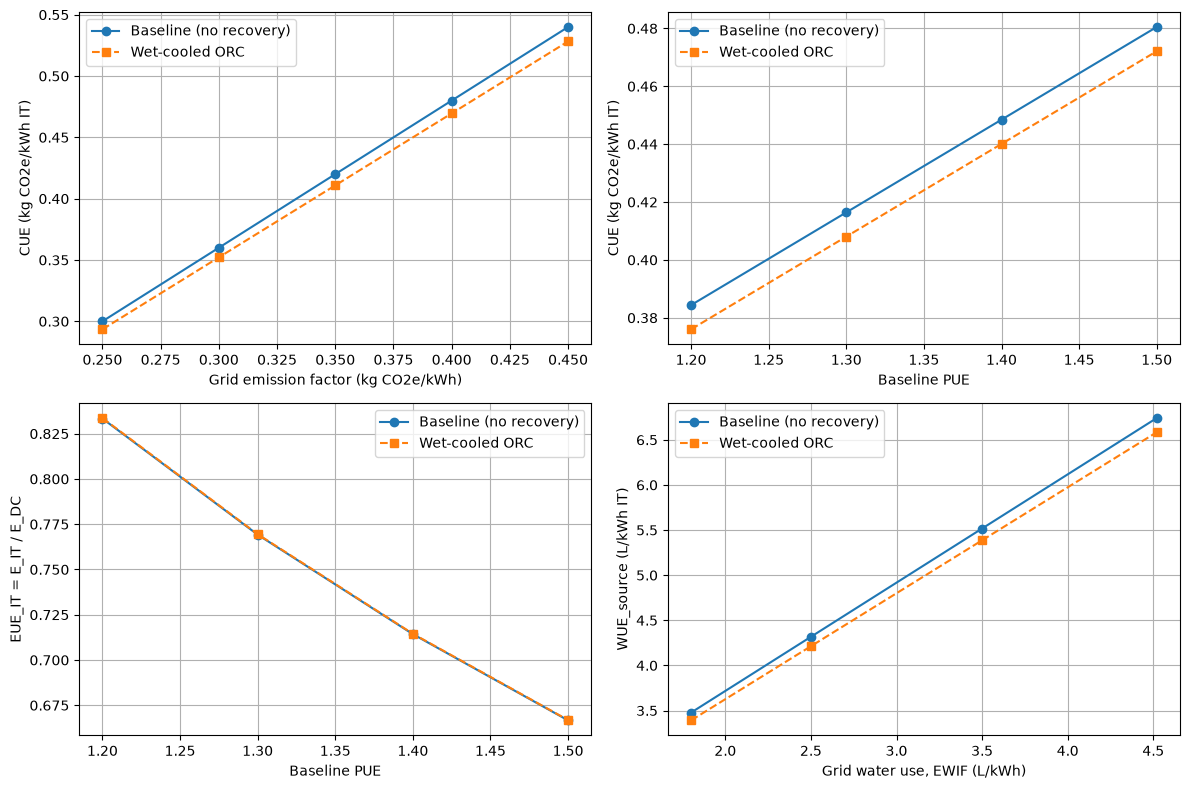

In [89]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Plot 1: CUE against the grid emission factor
efs = [0.25, 0.30, 0.35, 0.40, 0.45]
axes[0, 0].plot(efs, [e * imports_base / E_IT for e in efs], marker='o', label='Baseline (no recovery)')
axes[0, 0].plot(efs, [e * imports_orc / E_IT for e in efs], marker='s', linestyle='--', label='Wet-cooled ORC')
axes[0, 0].set_xlabel('Grid emission factor (kg CO2e/kWh)')
axes[0, 0].set_ylabel('CUE (kg CO2e/kWh IT)')

# Plot 2: CUE against the baseline PUE
pues = [1.2, 1.3, 1.4, 1.5]
axes[0, 1].plot(pues, [EF_grid * (p * E_IT) / E_IT for p in pues], marker='o', label='Baseline (no recovery)')
axes[0, 1].plot(pues, [EF_grid * (p * E_IT + par_change - E_ORC) / E_IT for p in pues], marker='s', linestyle='--', label='Wet-cooled ORC')
axes[0, 1].set_xlabel('Baseline PUE')
axes[0, 1].set_ylabel('CUE (kg CO2e/kWh IT)')

# Plot 3: EUE against the baseline PUE (EUE = (E_IT + Q_reuse) / E_DC, and Q_reuse = 0)
axes[1, 0].plot(pues, [(E_IT + Q_reuse_kWh) / (p * E_IT) for p in pues], marker='o', label='Baseline (no recovery)')
axes[1, 0].plot(pues, [(E_IT + Q_reuse_kWh) / (p * E_IT + par_change) for p in pues], marker='s', linestyle='--', label='Wet-cooled ORC')
axes[1, 0].set_xlabel('Baseline PUE')
axes[1, 0].set_ylabel('EUE_IT = E_IT / E_DC')

# Plot 4: WUE (source) against the grid water use
ewifs = [1.8, 2.5, 3.5, 4.52]
axes[1, 1].plot(ewifs, [(evap_base_L + w * imports_base) / E_IT for w in ewifs], marker='o', label='Baseline (no recovery)')
axes[1, 1].plot(ewifs, [(evap_orc_L + w * imports_orc) / E_IT for w in ewifs], marker='s', linestyle='--', label='Wet-cooled ORC')
axes[1, 1].set_xlabel('Grid water use, EWIF (L/kWh)')
axes[1, 1].set_ylabel('WUE_source (L/kWh IT)')

for ax in axes.flatten():
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.savefig("sensitivity.png", dpi=150)
plt.show()


## Step 8: Comparison bar charts
Bars compare the annual totals and show each indicator's percentage change from the baseline. The ORC's effect is a few percent at most, and that is the result.

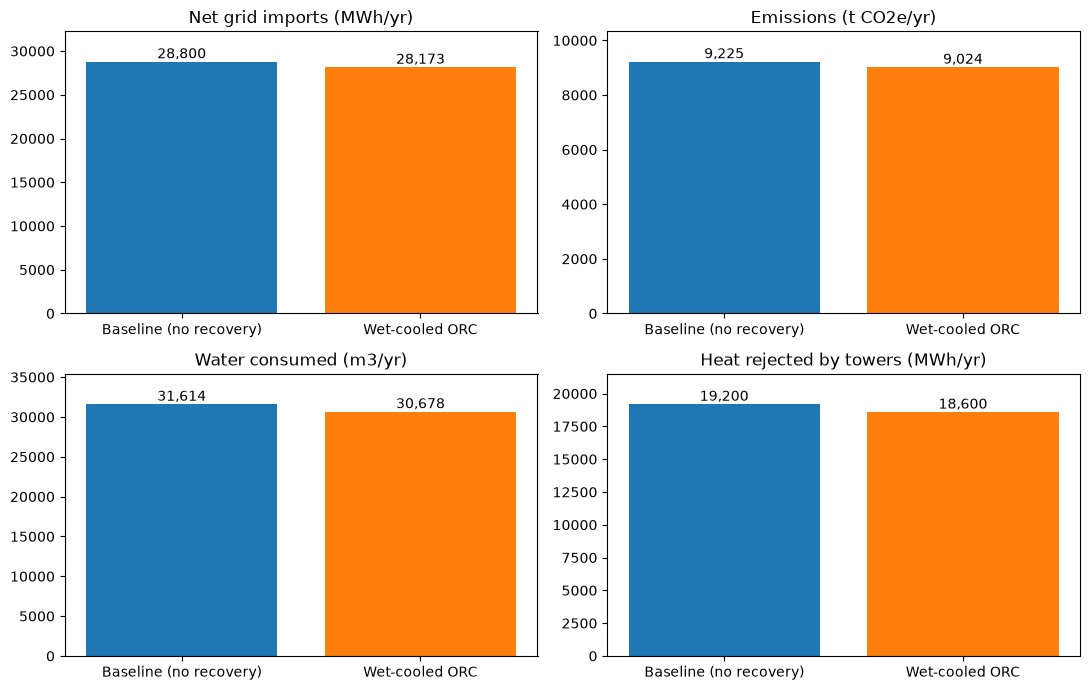

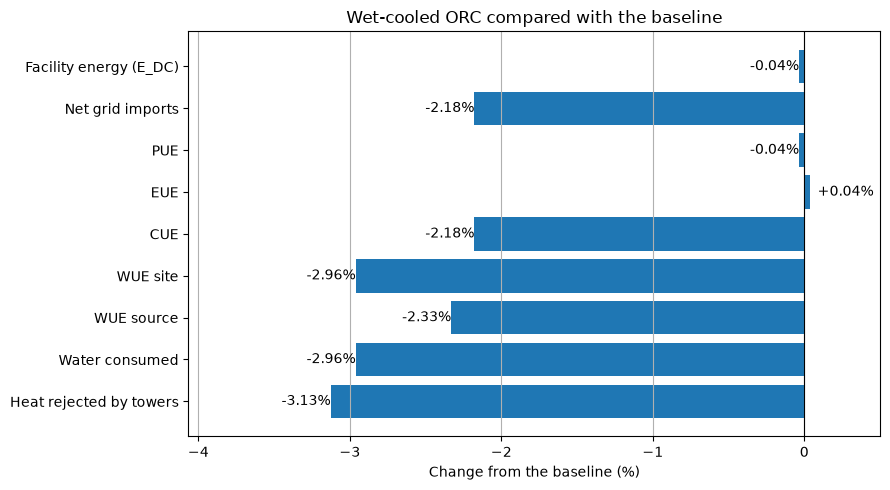

In [90]:
base_col = results['Baseline (no recovery)']
orc_col  = results['Wet-cooled ORC']
colours = ['tab:blue', 'tab:orange']          # same colours as the line plots: baseline, ORC

# Figure 1: annual totals, baseline next to the ORC case (bars start at zero)
items  = ['Net grid imports (MWh)', 'Emissions (t CO2e/yr)',
          'Water consumed = evaporation (m3/yr)', 'Heat rejected by towers (MWh)']
titles = ['Net grid imports (MWh/yr)', 'Emissions (t CO2e/yr)',
          'Water consumed (m3/yr)', 'Heat rejected by towers (MWh/yr)']
fig1, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, item, title in zip(axes.flatten(), items, titles):
    values = [base_col[item], orc_col[item]]
    bars = ax.bar(['Baseline (no recovery)', 'Wet-cooled ORC'], values, color=colours)
    ax.set_title(title)
    ax.set_ylim(0, max(values) * 1.12)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value, format(value, ',.0f'), ha='center', va='bottom')
plt.tight_layout()
plt.savefig("comparison_bars.png", dpi=150)
plt.show()

# Figure 2: change from the baseline for every indicator, in percent
names = ['Facility energy (E_DC)', 'Net grid imports', 'PUE', 'EUE', 'CUE', 'WUE site', 'WUE source',
         'Water consumed', 'Heat rejected by towers']
keys  = ['E_DC (MWh)', 'Net grid imports (MWh)', 'PUE = E_DC/E_IT', 'EUE_IT = (E_IT+Q_reuse)/E_DC',
         'CUE = G_DC/E_IT (kg CO2e/kWh IT)', 'WUE_site (L/kWh IT)', 'WUE_source (L/kWh IT)',
         'Water consumed = evaporation (m3/yr)', 'Heat rejected by towers (MWh)']
percent_change = [(orc_col[k] / base_col[k] - 1) * 100 for k in keys]

fig2, ax2 = plt.subplots(figsize=(9, 5))
bars = ax2.barh(names, percent_change, color='tab:blue')
ax2.axvline(0, color='black', linewidth=0.8)
ax2.invert_yaxis()                             # first item at the top
ax2.set_xlim(min(percent_change) * 1.3, max(max(percent_change) * 1.5, 0.5))   # leave room for the labels
ax2.set_xlabel('Change from the baseline (%)')
ax2.set_title('Wet-cooled ORC compared with the baseline')
for bar, value in zip(bars, percent_change):
    ax2.text(value, bar.get_y() + bar.get_height() / 2, '  ' + format(value, '+.2f') + '%',
             va='center', ha='left' if value >= 0 else 'right')
ax2.grid(True, axis='x')
plt.tight_layout()
plt.savefig("percent_change.png", dpi=150)
plt.show()
